# RISKY: 30-day hospital readmission, complete data science pipeline
**Author:** Karina Roade · QH0636 Data Science (resit)

**Research question.** How well can supervised machine learning models identify diabetic hospital encounters that are followed by readmission within 30 days, and what trade-offs between detection and false alarms do they involve?

**Objectives.**
1. Clean and prepare a messy healthcare dataset without leaking test information.
2. Explore patterns linked to early readmission with appropriate visualisations.
3. Train and justify three classification algorithms.
4. Evaluate and critically compare them with metrics suited to an imbalanced target.

**Dataset.** Diabetes 130-US Hospitals (1999–2008), UCI Machine Learning Repository: 101,766 encounters, 50 columns. After removing the 1,652 encounters that ended in the patient's death (readmission impossible), 100,114 encounters are analysed.

**Response variable.** The dataset has **one** response variable, `readmitted`, with **three** classes: `<30` (readmitted within 30 days), `>30` (readmitted after 30 days) and `NO`. This project models a **binary** target derived from it: `early_readmission = 1` if `readmitted == "<30"`, otherwise `0`.

**How to run.** Open this notebook from the project folder (the folder containing `data/` and `outputs/`) and choose *Run All*. It needs the packages in `requirements.txt`. The standalone scripts (`train_models.py` and the others, see `README.md`) produce the saved files in `outputs/`; this notebook repeats the same steps with every result shown inline, and checks that its numbers match the saved outputs.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder

ROOT = Path.cwd()                       # the notebook is run from the project folder
DATA = ROOT / 'data' / 'diabetic_data.csv'
OUT = ROOT / 'outputs'
assert DATA.exists(), f'Run this notebook from the project folder; {DATA} not found'
pd.set_option('display.max_columns', 60)
print('Project folder:', ROOT)

Project folder: /home/runner/work/effective-memory/effective-memory


## 2. Load the original data
`?` marks a missing value in this file. `keep_default_na=False` stops pandas from turning the text `None` into a missing value: in `max_glu_serum` and `A1Cresult`, `None` means *the test was not performed*, which is information, not missingness.

In [2]:
raw = pd.read_csv(DATA, na_values=['?'], keep_default_na=False, low_memory=False)
print('Shape:', raw.shape)
numeric_cols = raw.select_dtypes(include='number').columns.tolist()
categorical_cols = [c for c in raw.columns if c not in numeric_cols]
print(f'{len(numeric_cols)} numerical columns, {len(categorical_cols)} categorical columns')
raw.head()

Shape: (101766, 50)
13 numerical columns, 37 categorical columns


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 3. Response variable: one column, three classes, mapped to a binary target

In [3]:
print(raw['readmitted'].value_counts().reindex(['<30', '>30', 'NO']).to_string())
y_all = (raw['readmitted'] == '<30').astype(int)
print(f'\nBinary target early_readmission: {y_all.sum():,} positives out of {len(y_all):,} '
      f'({y_all.mean():.2%}).')
print(f'Predicting "no early readmission" for everyone would be {1 - y_all.mean():.2%} accurate '
      'while detecting no positive case, so accuracy alone is misleading.')

readmitted
<30    11357
>30    35545
NO     54864

Binary target early_readmission: 11,357 positives out of 101,766 (11.16%).
Predicting "no early readmission" for everyone would be 88.84% accurate while detecting no positive case, so accuracy alone is misleading.


## 4. Data quality and cleaning
Encounters that ended in the patient's death are removed because readmission is impossible (none of the 1,652 was readmitted); hospice discharges are kept because 5.6% of them were readmitted within 30 days. Strack et al. (2014) excluded both groups.

The cleaning steps live in `make_clean_dataset.py` so that the notebook, the scripts and the saved cleaned file all use exactly the same rules. Missing values are **not** imputed here: imputers are fitted inside the model pipelines on training data only, to avoid leaking test information.

In [4]:
from make_clean_dataset import clean

missing = raw.isna().sum()
missing = (pd.DataFrame({'missing_count': missing, 'missing_%': (missing / len(raw) * 100).round(2)})
           .query('missing_count > 0').sort_values('missing_count', ascending=False))
print('Missing values after mapping "?" (before cleaning):')
display(missing)

print('Lab tests: "None" = not performed (kept as a category)')
for col in ['max_glu_serum', 'A1Cresult']:
    print(col, raw[col].value_counts().to_dict())
print('gender:', raw['gender'].value_counts().to_dict())

df, cleaning_log = clean(raw)
display(cleaning_log)
df.to_csv(ROOT / 'data' / 'diabetic_data_cleaned.csv', index=False)
print('Cleaned dataset saved: data/diabetic_data_cleaned.csv', df.shape)

Missing values after mapping "?" (before cleaning):


,missing_count,missing_%
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


Lab tests: "None" = not performed (kept as a category)
max_glu_serum {'None': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}
A1Cresult {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}
gender: {'Female': 54708, 'Male': 47055, 'Unknown/Invalid': 3}


,step,detail
0,"""?"" converted to missing","192,849 cells now missing"
1,"gender ""Unknown/Invalid"" recoded as missing",3 encounters
2,weight column dropped,96.86% missing
3,encounters ending in death removed (readmissio...,"1,652 encounters removed; 100,114 remain"
4,binary target added (<30 = 1; >30 and NO = 0),"11,357 positives (11.34%)"
5,duplicate checks,0 duplicate rows; 0 duplicate encounter IDs; 7...


Cleaned dataset saved: data/diabetic_data_cleaned.csv (100114, 50)


In [5]:
# Why remove deceased patients but keep hospice discharges? Readmission rate by discharge type:
names = {11: 'Expired', 19: 'Expired at home (hospice)', 20: 'Expired in facility (hospice)', 21: 'Expired, place unknown',
         13: 'Hospice / home', 14: 'Hospice / medical facility'}
check = (raw[raw['discharge_disposition_id'].isin(names)]
         .assign(discharge=lambda d: d['discharge_disposition_id'].map(names), early=lambda d: d['readmitted'].eq('<30'))
         .groupby('discharge')['early'].agg(encounters='size', readmitted_within_30_days='sum'))
display(check)
print(f'Dataset average early-readmission rate: {(raw["readmitted"] == "<30").mean():.1%}')

,encounters,readmitted_within_30_days
discharge,,
Expired,1642,0
Expired at home (hospice),8,0
Expired in facility (hospice),2,0
Hospice / home,399,19
Hospice / medical facility,372,24


Dataset average early-readmission rate: 11.2%


**Reading.** No deceased patient was readmitted, so those encounters would be labelled *no readmission* by construction and would make the models look better than they are. Hospice discharges are readmitted less often than average but not never, so they remain in the analysis.

## 5. Exploratory data analysis

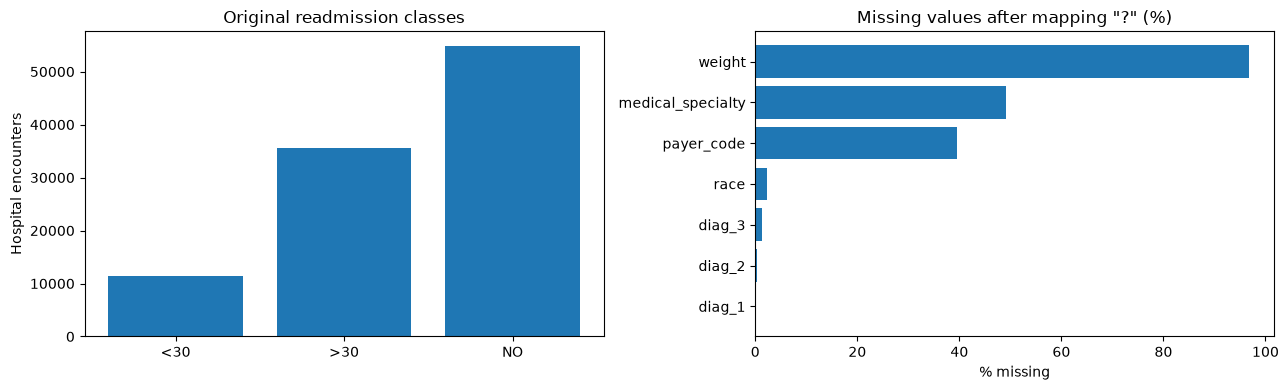

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = raw['readmitted'].value_counts().reindex(['<30', '>30', 'NO'])
axes[0].bar(counts.index, counts.values)
axes[0].set_title('Original readmission classes'); axes[0].set_ylabel('Hospital encounters')
top = missing.head(8).iloc[::-1]
axes[1].barh(top.index, top['missing_%'])
axes[1].set_title('Missing values after mapping "?" (%)'); axes[1].set_xlabel('% missing')
plt.tight_layout(); plt.show()

**Reading.** Only about one encounter in nine is an early readmission (class imbalance). Weight is almost entirely missing and is dropped; medical specialty and payer code are about half and two-fifths missing and are imputed inside the pipelines.

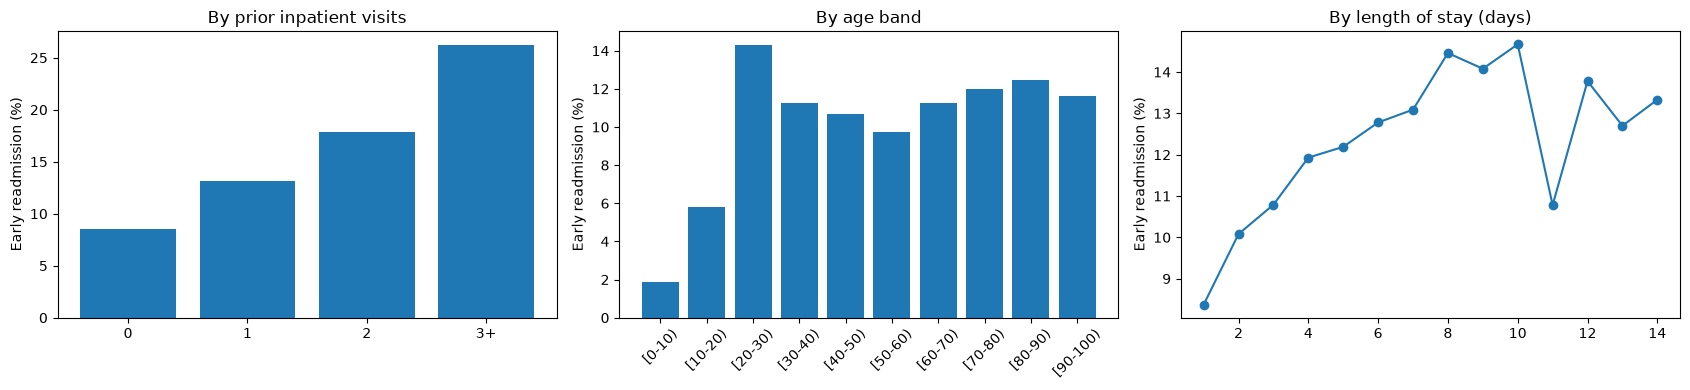

number_inpatient,0,1,2,3+
encounters,66672.00,19163.00,7382.00,6897.00
rate_%,8.56,13.17,17.87,26.23


age,[0-10),[10-20),[20-30),[30-40),[40-50),[50-60),[60-70),[70-80),[80-90),[90-100)
encounters,160.00,690.0,1650.0,3765.00,9626.00,17102.00,22185.00,25562.00,16706.00,2668.00
rate_%,1.88,5.8,14.3,11.26,10.67,9.75,11.28,12.01,12.44,11.62


time_in_hospital,1,2,3,4,5,6,7,8,9,10,11,12,13,14
encounters,13878.00,16976.00,17546.00,13775.00,9834.00,7425.00,5744.00,4323.00,2927.00,2290.00,1809.00,1401.00,1173.0,1013.00
rate_%,8.37,10.08,10.79,11.93,12.19,12.78,13.09,14.46,14.08,14.67,10.78,13.78,12.7,13.33


In [7]:
def rate_table(series):
    t = df.groupby(series, observed=True)['early_readmission'].agg(encounters='size', rate='mean')
    t['rate_%'] = (t.pop('rate') * 100).round(2)
    return t

prior = rate_table(pd.cut(df['number_inpatient'], [-1, 0, 1, 2, 100], labels=['0', '1', '2', '3+']))
age = rate_table(df['age'])
stay = rate_table(df['time_in_hospital'])

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(prior.index.astype(str), prior['rate_%']); axes[0].set_title('By prior inpatient visits')
axes[1].bar(age.index.astype(str), age['rate_%']); axes[1].set_title('By age band'); axes[1].tick_params(axis='x', rotation=45)
axes[2].plot(stay.index, stay['rate_%'], marker='o'); axes[2].set_title('By length of stay (days)')
for ax in axes: ax.set_ylabel('Early readmission (%)')
plt.tight_layout(); plt.show()
display(prior.T); display(age.T); display(stay.T)

**Reading.** The rate rises from about 9% with no prior inpatient visit to about 26% with three or more, the strongest pattern in the data. Age bands differ only modestly (the youngest bands are small), and longer stays are associated with higher rates up to about 10 days. These are associations, not causal effects: illness severity is not fully measured and can explain both.

## 6. Modelling set-up
* **Features:** all columns except the target, the original `readmitted`, the identifiers `encounter_id` and `patient_nbr`, and `weight` (already dropped).
* **Patient-grouped split:** 70,439 patients have 100,114 encounters, so encounters of one patient must not appear in both training and test sets. `GroupShuffleSplit` keeps 20% of **patients** for testing.
* **Pipelines:** imputation, scaling and encoding are fitted on training data only. Numerical: median imputation (+ scaling for the linear-preprocessing models). Categorical: most-frequent imputation, then one-hot encoding (rare categories under 1,000 grouped) or ordinal encoding for gradient boosting.
* **Algorithms:**
  * *Logistic Regression*: interpretable linear baseline, balanced class weights.
  * *Random Forest*: averages many decision trees to capture non-linear effects, balanced class weights.
  * *HistGradientBoostingClassifier*: scikit-learn's histogram-based gradient boosting (the same family as XGBoost/LightGBM); builds trees sequentially to model feature interactions. No class weighting.

In [8]:
y = df['early_readmission']
X = df.drop(columns=['early_readmission', 'readmitted', 'encounter_id', 'patient_nbr'])
cat = X.select_dtypes(include=['object', 'string']).columns.tolist()
num = [c for c in X.columns if c not in cat]

tr, te = next(GroupShuffleSplit(n_splits=1, test_size=.20, random_state=42).split(X, y, groups=df['patient_nbr']))
Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
assert set(df['patient_nbr'].iloc[tr]).isdisjoint(df['patient_nbr'].iloc[te]), 'patient overlap!'
print(f'{len(num)} numerical and {len(cat)} categorical features')
print(f'Train: {len(tr):,} encounters (prevalence {ytr.mean():.4f}) | Test: {len(te):,} encounters (prevalence {yte.mean():.4f})')
print('No patient appears in both sets.')

linear_prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=1000))]), cat)])
tree_prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))]), cat)])

def make_models():
    return {
        'Logistic Regression': Pipeline([('prep', linear_prep), ('model', LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42))]),
        'Random Forest': Pipeline([('prep', linear_prep), ('model', RandomForestClassifier(n_estimators=35, max_depth=12, min_samples_leaf=8, class_weight='balanced_subsample', random_state=42, n_jobs=2))]),
        'Gradient Boosting': Pipeline([('prep', tree_prep), ('model', HistGradientBoostingClassifier(max_iter=65, max_leaf_nodes=12, l2_regularization=1.0, random_state=42))]),
    }

11 numerical and 35 categorical features
Train: 80,039 encounters (prevalence 0.1131) | Test: 20,075 encounters (prevalence 0.1148)
No patient appears in both sets.


## 7. Training and evaluation on held-out patients (threshold 0.50)

In [9]:
results, probs = [], {}
for name, pipe in make_models().items():
    pipe.fit(Xtr, ytr)
    p = pipe.predict_proba(Xte)[:, 1]; pred = (p >= 0.5).astype(int)
    probs[name] = p
    results.append({'model': name, 'accuracy': accuracy_score(yte, pred), 'balanced_accuracy': balanced_accuracy_score(yte, pred),
                    'precision': precision_score(yte, pred, zero_division=0), 'recall': recall_score(yte, pred, zero_division=0),
                    'f1': f1_score(yte, pred, zero_division=0), 'roc_auc': roc_auc_score(yte, p),
                    'pr_auc_average_precision': average_precision_score(yte, p), 'brier_score': brier_score_loss(yte, p)})
results = pd.DataFrame(results)
display(results.round(3))

# Reproducibility check against the files written by train_models.py
saved = pd.read_csv(OUT / 'model_comparison.csv')
saved_preds = pd.read_csv(OUT / 'test_predictions.csv')
same_metrics = np.allclose(results.drop(columns='model').to_numpy(), saved.drop(columns='model').to_numpy(), atol=1e-9)
same_preds = all(np.allclose(probs[m], saved_preds[m], atol=1e-9) for m in probs)
print('Matches outputs/model_comparison.csv:', same_metrics, '| matches outputs/test_predictions.csv:', same_preds)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision,brier_score
0,Logistic Regression,0.645,0.601,0.171,0.543,0.260,0.641,0.200,0.230
1,Random Forest,0.670,0.608,0.180,0.528,0.269,0.647,0.193,0.217
2,Gradient Boosting,0.885,0.502,0.615,0.003,0.007,0.664,0.223,0.097


Matches outputs/model_comparison.csv: True | matches outputs/test_predictions.csv: True


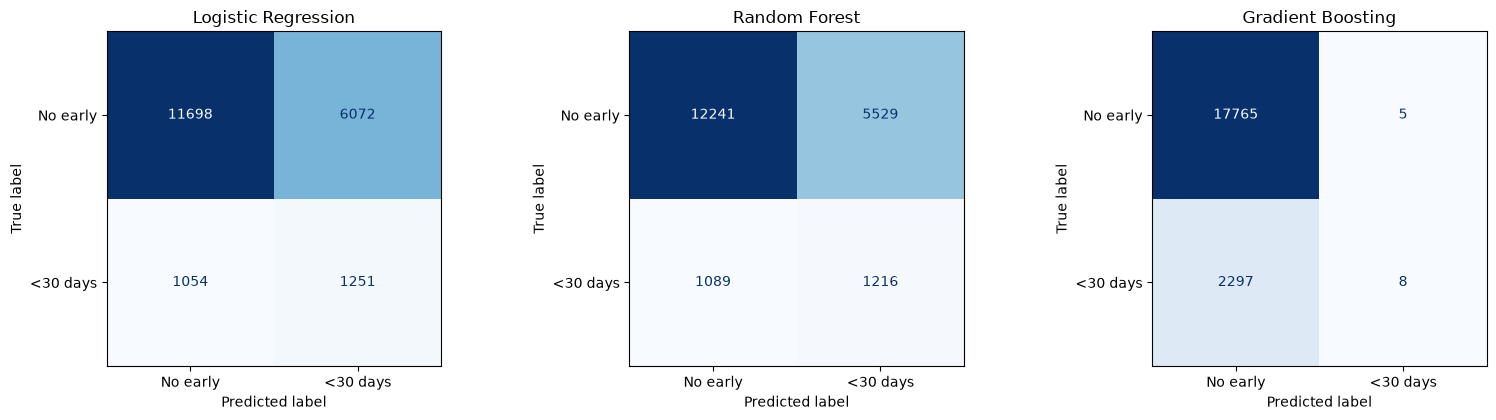

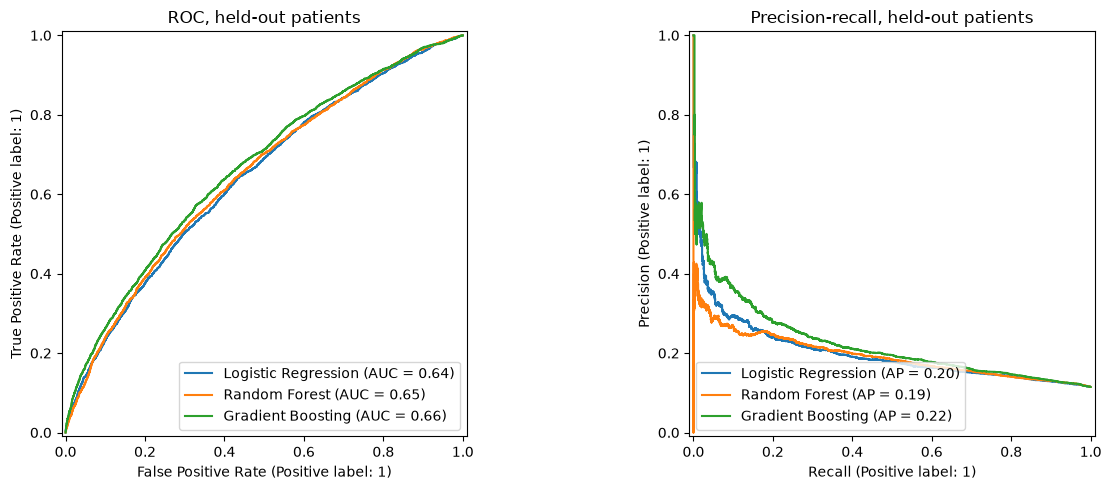

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (name, p) in zip(axes, probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(yte, (p >= 0.5).astype(int)),
                           display_labels=['No early', '<30 days']).plot(ax=ax, values_format='d', cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probs.items():
    RocCurveDisplay.from_predictions(yte, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(yte, p, name=name, ax=axes[1])
axes[0].set_title('ROC, held-out patients'); axes[1].set_title('Precision-recall, held-out patients')
plt.tight_layout(); plt.show()

**Reading.** Gradient Boosting ranks encounters best (highest ROC-AUC and average precision) but, at the 0.50 threshold, detects only 8 of 2,305 early readmissions; its high accuracy mostly reflects the majority class. Logistic Regression and Random Forest detect about half of the readmissions but with low precision (about one flagged encounter in six is a true readmission). No model gives a clinically acceptable balance on its own.

## 8. Threshold sensitivity (descriptive only, no threshold is selected on the test set)

In [11]:
rows = []
for name, p in probs.items():
    for t in [0.10, 0.20, 0.30, 0.40, 0.50]:
        z = (p >= t).astype(int); tn, fp, fn, tp = confusion_matrix(yte, z, labels=[0, 1]).ravel()
        rows.append({'model': name, 'threshold': t, 'precision': precision_score(yte, z, zero_division=0),
                     'recall': recall_score(yte, z, zero_division=0), 'f1': f1_score(yte, z, zero_division=0),
                     'tp': tp, 'fp': fp, 'tn': tn, 'fn': fn})
thresholds = pd.DataFrame(rows)
display(thresholds.round(3))
print('Matches outputs/threshold_sensitivity.csv:',
      np.allclose(thresholds.drop(columns='model').to_numpy(float),
                  pd.read_csv(OUT / 'threshold_sensitivity.csv').drop(columns='model').to_numpy(float)))

,model,threshold,precision,recall,f1,tp,fp,tn,fn
0,Logistic Regression,0.1,0.115,1.000,0.206,2305,17770,0,0
1,Logistic Regression,0.2,0.115,0.999,0.206,2303,17711,59,2
2,Logistic Regression,0.3,0.120,0.973,0.214,2242,16428,1342,63
3,Logistic Regression,0.4,0.138,0.829,0.236,1910,11968,5802,395
4,Logistic Regression,0.5,0.171,0.543,0.260,1251,6072,11698,1054
5,Random Forest,0.1,0.115,1.000,0.206,2305,17770,0,0
6,Random Forest,0.2,0.115,1.000,0.206,2305,17744,26,0
7,Random Forest,0.3,0.119,0.983,0.213,2266,16755,1015,39
8,Random Forest,0.4,0.135,0.844,0.233,1945,12464,5306,360
9,Random Forest,0.5,0.180,0.528,0.269,1216,5529,12241,1089


Matches outputs/threshold_sensitivity.csv: True


## 9. Calibration check (probabilities are **not** recalibrated)

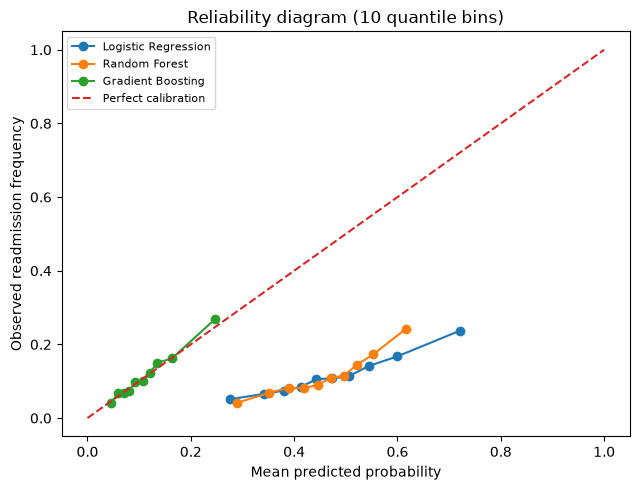

,model,brier_score,mean_predicted,observed_rate
0,Logistic Regression,0.230,0.470,0.115
1,Random Forest,0.217,0.456,0.115
2,Gradient Boosting,0.097,0.112,0.115


Reference Brier score for always predicting the prevalence (0.115): 0.102


In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, p in probs.items():
    obs, est = calibration_curve(yte, p, n_bins=10, strategy='quantile')
    ax.plot(est, obs, marker='o', label=name)
ax.plot([0, 1], [0, 1], '--', label='Perfect calibration')
ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed readmission frequency')
ax.set_title('Reliability diagram (10 quantile bins)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
prev = yte.mean()
cal = results[['model', 'brier_score']].assign(mean_predicted=[probs[m].mean() for m in results['model']], observed_rate=prev)
display(cal.round(3))
print(f'Reference Brier score for always predicting the prevalence ({prev:.3f}): {prev * (1 - prev):.3f}')

**Reading.** Gradient Boosting's probabilities follow observed rates closely. Logistic Regression and Random Forest strongly overestimate risk (mean prediction about 0.46 against an observed 0.115), as expected after balanced class weighting, so their probabilities should not be read as risks without recalibration.

## 10. Robustness: patient-grouped 3-fold cross-validation on the training set only (takes a few minutes)

In [13]:
Xtrain, ytrain = Xtr.reset_index(drop=True), ytr.reset_index(drop=True)
gtrain = df['patient_nbr'].iloc[tr].reset_index(drop=True)
cv_rows = []
for fold, (it, iv) in enumerate(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42).split(Xtrain, ytrain, groups=gtrain), 1):
    for name, model in make_models().items():
        model.fit(Xtrain.iloc[it], ytrain.iloc[it])
        cv_rows.append({'fold': fold, 'model': name, 'roc_auc': roc_auc_score(ytrain.iloc[iv], model.predict_proba(Xtrain.iloc[iv])[:, 1])})
cv = pd.DataFrame(cv_rows).groupby('model')['roc_auc'].agg(['mean', 'std']).round(3)
display(cv)

,mean,std
model,,
Gradient Boosting,0.669,0.004
Logistic Regression,0.650,0.005
Random Forest,0.654,0.003


**Reading.** Cross-validated ROC-AUC values are within about 0.01 of the test-set values, with low variation between folds, so the ranking of the models is stable rather than an artefact of one split.

## 11. Summary against the objectives
1. **Cleaning:** placeholders, an uninformative column, invalid gender codes, encounters ending in death and repeat patients were handled; imputation is fitted on training data only; the cleaned file is saved in `data/`.
2. **EDA:** prior inpatient use shows the strongest association with early readmission; age and length of stay show weaker patterns; all are associations only.
3. **Modelling:** three justified algorithms were trained in leakage-safe pipelines.
4. **Evaluation:** the models discriminate modestly (ROC-AUC 0.64–0.66). Their usefulness depends on the threshold and the relative cost of missed readmissions versus false alarms, which is a clinical decision. Results are reproducible and match the saved outputs.